# European Option Pricing: Monte Carlo vs Black-Scholes

This notebook prices a European call option with two methods:

1. **Monte Carlo simulation**: simulate many possible future prices of the underlying asset and average the option's payoff.
2. **Black-Scholes formula**: compute the exact price with a closed-form formula.

The goal is to show that the Monte Carlo estimate converges to the Black-Scholes price as the number of simulations increases.

## Setup and parameters

We price an at-the-money European call option with the following parameters:

| Parameter | Symbol | Value |
|---|---|---|
| Current price of the underlying | $S_0$ | 100 |
| Strike price | $K$ | 100 |
| Maturity (years) | $T$ | 1 |
| Risk-free rate | $r$ | 5% |
| Volatility | $\sigma$ | 20% |

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(42)

T = 1
strike = 100
r = 0.05
sigma = 0.2
S_0 = 100


## 1. Monte Carlo pricing

A European call gives the right to buy the underlying asset at the strike price $K$ at maturity $T$. If the price at maturity $S_T$ is above $K$, the holder gains $S_T - K$; otherwise the option is worthless. The payoff is:

$$\text{payoff} = \max(S_T - K,\ 0)$$

The idea of Monte Carlo is simple:
1. Simulate many possible prices at maturity, using the Black-Scholes model:
$$S_T = S_0 \exp\left(\left(r - \frac{\sigma^2}{2}\right)T + \sigma\sqrt{T}\, Z\right), \quad Z \sim \mathcal{N}(0,1)$$
2. Compute the payoff for each simulated price
3. Take the average of the payoffs
4. Discount it to today by multiplying by $e^{-rT}$

By the law of large numbers, the more simulations we run, the closer the estimate gets to the true price.

In [34]:
def monte_carlo(S_0, strike, T, r, sigma, n):
    
    """Price of a European call option using Monte-Carlo estimation"""
    
    vol_correction = sigma**2 / 2
    drift = r - vol_correction

    random_normal = rng.standard_normal(size=n)
    future_prices = S_0 * np.exp(drift*T + np.sqrt(T)*sigma*random_normal)
    payoff = np.maximum(future_prices-strike, 0)
    mean_payoff = payoff.mean()
    mc_price = mean_payoff*np.exp(-r*T)
    
    return mc_price

print(monte_carlo(S_0, strike, T, r, sigma, 100000))

10.420541193153111


## 2. Black-Scholes formula

The Black-Scholes formula gives the exact price of a European call, without any simulation:

$$C = S_0\, N(d_1) - K e^{-rT} N(d_2)$$

with

$$d_1 = \frac{\ln(S_0/K) + (r + \sigma^2/2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

where $N$ is the cumulative distribution function of the standard normal distribution.

We use this exact price as a benchmark to check the Monte Carlo estimate.

In [35]:
def black_scholes(S_0, strike, T, r, sigma):
    
    """Price of a European call option using the Black-Scholes formula."""
    
    d1 = (np.log(S_0/strike) + (r+sigma**2/2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    price_call = S_0*norm.cdf(d1) - strike*np.exp(-r*T)*norm.cdf(d2)

    return price_call

print(black_scholes(S_0, strike, T, r, sigma))

10.450583572185565


## 3. Convergence of the Monte Carlo estimate

Computes the Monte Carlo price for a number of simulations ranging from $10^2$ to $10^6$ (log-spaced), and compares it with the Black-Scholes price. Each estimate uses independent random draws.

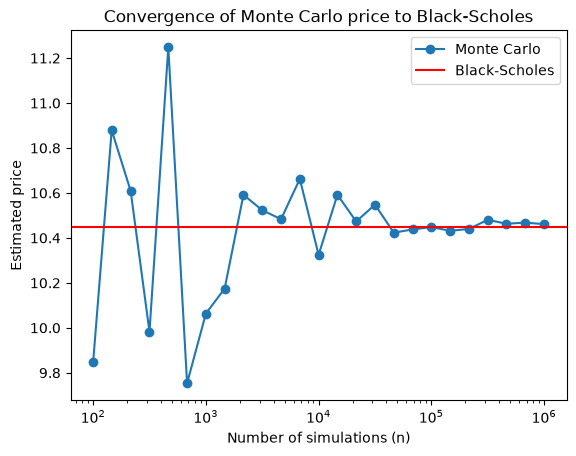

In [36]:
n_values = np.logspace(2, 6, 25).astype(int)
mc_prices = []
for n in n_values:
    mc_prices.append(monte_carlo(S_0, strike, T, r, sigma, n))

fig, ax = plt.subplots()
ax.plot(n_values, mc_prices, "o-", label="Monte Carlo")
ax.axhline(y=black_scholes(S_0, strike, T, r, sigma), color="r", label="Black-Scholes")
ax.legend()
ax.set_xscale("log")
ax.set_xlabel("Number of simulations (n)")
ax.set_ylabel("Estimated price")
ax.set_title("Convergence of Monte Carlo price to Black-Scholes")
plt.savefig("convergence.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

- Both methods give the same price: about **10.45** for this option.
- With few simulations, the Monte Carlo estimate is very noisy (errors of about ±0.9 around $n = 10^2$). The error shrinks as $n$ grows (about ±0.15 around $n = 10^4$, and ±0.02 around $n = 10^6$).
- This illustrates that the Monte Carlo error decreases as $1/\sqrt{n}$: dividing the error by 10 requires 100 times more simulations.
- The closed-form formula is instantaneous and exact, but only exists for simple options. Monte Carlo is slower, but works for almost any payoff, which makes it essential for pricing exotic options.

**Next steps:** confidence intervals for the Monte Carlo estimate, put options and put-call parity, the Greeks (delta, gamma, vega), and variance reduction techniques.